# 02 · Manifold — scFates trajectory (non-branching curve)

Load the processed manifold → score developmental modules + graph-smooth → confirm the developmental axis is cell-cycle-free → fit a scFates **curve** (topology matched to a non-branching manifold; PPT tree cross-check finds 0 branch nodes) → derive the root from the Gast/pSom-high pole → pseudotime.

In [1]:
import os, sys, glob, io, contextlib, warnings
warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load manifold, re-score modules, graph-smooth for geography

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']
from numpy.linalg import svd
c = xy - xy.mean(0); u,s,vt = svd(c, full_matrices=False)
print('UMAP principal-axis ratio (major/minor singular value): %.2f' % (s[0]/s[1]))
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print('%s: %d/%d genes present' % (lab, g.size, feat[src].size))
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('raw module means (honest readout):', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

whole malignant manifold: 633 cells on the joint embedding
UMAP principal-axis ratio (major/minor singular value): 1.66
Gast: 69/81 genes present
pSom: 80/98 genes present
Crest: 92/104 genes present
raw module means (honest readout): {'Gast': -0.0125, 'pSom': 0.0646, 'Crest': -0.0345}


### Developmental axis is cell-cycle-free
Module scores could be a proliferation gradient in disguise. Show (a) module↔cell-cycle-programme gene overlap, (b) module correlations survive on non-cycling (G1) cells only. If they do, keep the whole manifold — no scoping.

In [4]:
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print('  %s vs %s: r = %+.2f' % (a,b,r))
s_genes = set(('MCM5 PCNA TYMS FEN1 MCM2 MCM4 RRM1 UNG GINS2 MCM6 CDCA7 DTL PRIM1 UHRF1 HELLS RFC2 RPA2 '
    'NASP RAD51AP1 GMNN WDR76 SLBP CCNE2 UBR7 POLD3 MSH2 ATAD2 RAD51 RRM2 CDC45 CDC6 EXO1 TIPIN DSCC1 '
    'BLM CASP8AP2 USP1 CLSPN POLA1 CHAF1B BRIP1 E2F8').split())
g2m_genes = set(('HMGB2 CDK1 NUSAP1 UBE2C BIRC5 TPX2 TOP2A NDC80 CKS2 NUF2 CKS1B MKI67 TMPO CENPF TACC3 '
    'FAM64A SMC4 CCNB2 CKAP2L CKAP2 AURKB BUB1 KIF11 ANP32E TUBB4B GTSE1 KIF20B HJURP CDCA3 HN1 CDC20 TTK '
    'CDC25C KIF2C RANGAP1 NCAPD2 DLGAP5 CDCA2 CDCA8 ECT2 KIF23 HMMR AURKA PSRC1 ANLN LBR CKAP5 CENPE CTCF '
    'NEK2 G2E3 GAS2L3 CBX5 CENPA').split())
cc = s_genes | g2m_genes
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    ov = set(feat[src]) & cc
    print('  %s: %d/%d genes overlap the cell-cycle programme' % (lab, len(ov), len(set(feat[src]))))
noncyc = (adata.obs['phase'] == 'G1').values
print('  cycling fraction: %.3f | non-cycling cells: %d' % (adata.obs['cycling'].astype(str).eq('True').mean() if adata.obs['cycling'].dtype.name=='category' else (adata.obs['phase']!='G1').mean(), int(noncyc.sum())))
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r_all = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]
    r_nc  = np.corrcoef(adata.obs.loc[noncyc,a], adata.obs.loc[noncyc,b])[0,1]
    print('  %s vs %s: all r=%+.2f | non-cycling r=%+.2f' % (a,b,r_all,r_nc))
print('-> developmental axis is cell-cycle-free and survives on non-cycling cells; keep whole manifold (no scoping).')
sub = adata

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = +0.23
  Crest_sm vs Gast_sm: r = -0.80
  Crest_sm vs pSom_sm: r = -0.74
  Gast: 0/81 genes overlap the cell-cycle programme
  pSom: 2/98 genes overlap the cell-cycle programme
  Crest: 0/104 genes overlap the cell-cycle programme
  cycling fraction: 0.428 | non-cycling cells: 362
  Gast_sm vs pSom_sm: all r=+0.23 | non-cycling r=+0.26
  Crest_sm vs Gast_sm: all r=-0.80 | non-cycling r=-0.80
  Crest_sm vs pSom_sm: all r=-0.74 | non-cycling r=-0.76
-> developmental axis is cell-cycle-free and survives on non-cycling cells; keep whole manifold (no scoping).


### Topology — curve (non-branching), with a PPT-tree cross-check
A curve is the right primitive only if the manifold does not branch. Sweep the curve node count (tips/forks + a fold self-approach ratio >1 = fold-free), and independently fit a PPT tree — 0 branch nodes confirms non-branching. This avoids both failure modes in the testing log (tree-on-a-strip and curve-on-a-Y).

In [5]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks
for Nn in [15, 20, 30]:
    a2 = sub.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(a2, Nodes=Nn, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa, tips, forks = fold_diag(a2)
    print('curve N=%d: %d tips, %d forks | self-approach %.2f' % (Nn, tips, forks, sa))
a3 = sub.copy()
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(a3, method='ppt', Nodes=30, use_rep='X_umap', ppt_lambda=2000, ppt_sigma=0.5, seed=SEED, plot=False)
Bt = np.asarray(a3.uns['graph']['B'])
print('PPT tree Nodes=30 branch nodes: %d (0 = non-branching confirmed)' % int(((Bt>0).sum(0)>=3).sum()))
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print('chosen curve N=20: %d tips, %d forks | fold self-approach ratio = %.2f (>1 = fold-free)' % (tips, forks, sa))
assert forks == 0 and sa > 1, 'topology check failed'

curve N=15: 2 tips, 0 forks | self-approach 2.95
curve N=20: 2 tips, 0 forks | self-approach 2.84
curve N=30: 2 tips, 0 forks | self-approach 2.57
PPT tree Nodes=30 branch nodes: 0 (0 = non-branching confirmed)
chosen curve N=20: 2 tips, 0 forks | fold self-approach ratio = 2.84 (>1 = fold-free)


### Root at the Gast/pSom-high developmental origin
Score each curve tip by (Gast+pSom−Crest) on its neighbourhood; root at the argmax (early developmental pole). Crest is developmentally *late*, so the root is never at the Crest tip. Then pseudotime, and verify the developmental order Gast(0) → pSom → Crest(1) and that pseudotime is not a cycling gradient.

In [6]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print('tip %d: Gast=%+.4f pSom=%+.4f Crest=%+.4f' % (tp, *info[tp]))
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[s]); print('  %s: rho=%+.3f p=%.1e' % (s, rho, p))
tn = (t-t.min())/(t.max()-t.min())
for m,lab_ in [('Crest_sm','Neural-crest'),('pSom_sm','Somitogenesis'),('Gast_sm','Gastrulation')]:
    hi = sub.obs[m] >= sub.obs[m].quantile(0.9)
    print('%s-high decile mean pseudotime = %.2f' % (lab_, tn[hi.values].mean()))
cyc = np.maximum(pd.to_numeric(sub.obs['S_score'],errors='coerce').fillna(0).values,
                 pd.to_numeric(sub.obs['G2M_score'],errors='coerce').fillna(0).values)
rho_c,_ = spearmanr(t, cyc)
print('caveat: pseudotime vs cycling score rho = %+.2f (cell-cycle-free axis; not proliferation-driven)' % rho_c)
# rename milestones to biological identities
sub.obs['milestones'] = sub.obs['milestones'].astype(str)
ms = sub.obs.groupby('milestones', observed=True)['t'].mean().sort_values()
name_map = {ms.index[0]:'Body (Gast/pSom origin)', ms.index[-1]:'Neural-crest-like terminus'}
sub.obs['milestones'] = sub.obs['milestones'].map(lambda x: name_map.get(x, x)).astype('category')
print('milestones:', sub.obs['milestones'].value_counts().to_dict())

tip 0: Gast=-0.0186 pSom=+0.0602 Crest=-0.0232
tip 2: Gast=-0.0050 pSom=+0.0645 Crest=-0.0407
derived root = tip 2 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.857 p=4.8e-184
  pSom_sm: rho=-0.624 p=1.3e-69
  Crest_sm: rho=+0.921 p=2.5e-261
Neural-crest-high decile mean pseudotime = 0.99
Somitogenesis-high decile mean pseudotime = 0.33
Gastrulation-high decile mean pseudotime = 0.00
caveat: pseudotime vs cycling score rho = -0.03 (cell-cycle-free axis; not proliferation-driven)
milestones: {'Neural-crest-like terminus': 350, 'Body (Gast/pSom origin)': 283}


### Orientation check (house layout re-used from 01)

In [7]:
t = sub.obs['t'].values
r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
if r < 0:
    sub.obsm['X_umap_lin'][:,0] = -sub.obsm['X_umap_lin'][:,0]
    r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
assert abs(r) > 0.5, 'stored orientation not pseudotime-consistent (corr=%.2f)' % r
print('house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = %+.2f' % r)

house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = +0.98


### Serialize + deliverable `manifold.pdf` (pseudotime on house layout)

saved manifold.h5ad + manifold.pdf


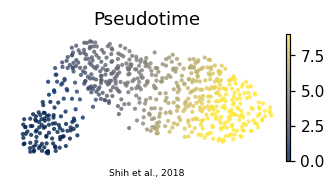

In [8]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Shih et al., 2018', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')